In [3]:
import sys
print(sys.executable)

/Users/kosunjin/BioAuditAnalyzer-2.0/.venv/bin/python


In [4]:

import io
import zipfile
import requests
import pandas as pd
import xml.etree.ElementTree as ET
from getpass import getpass

# GitHub에 노출되지 않도록 비밀번호 입력창 사용
api_key = getpass("OpenDART API 키 입력: ")

url = "https://opendart.fss.or.kr/api/corpCode.xml"

response = requests.get(
    url,
    params={"crtfc_key": api_key},
    timeout=30
)

if response.status_code != 200:
    raise RuntimeError(f"HTTP 오류: {response.status_code}")

if not zipfile.is_zipfile(io.BytesIO(response.content)):
    raise RuntimeError("ZIP 응답이 아닙니다. API 키와 요청 상태를 확인하세요.")

with zipfile.ZipFile(io.BytesIO(response.content)) as z:
    xml_file = next(
        name for name in z.namelist()
        if name.lower().endswith(".xml")
    )
    root = ET.fromstring(z.read(xml_file))

corp_df = pd.DataFrame([
    {child.tag: child.text for child in item}
    for item in root.findall("list")
])

target = corp_df[
    corp_df["corp_name"].str.contains(
        "알테오젠|대웅제약", na=False
    )
]

display(target[["corp_name", "corp_code", "stock_code"]])


OpenDART API 키 입력:  ········


,corp_name,corp_code,stock_code
97972,대웅제약,00427483,069620
111397,알테오젠바이오로직스,01645493,
113790,알테오젠,00989619,196170


In [5]:

def get_financial_statements(corp_code, year=2025):
    url = "https://opendart.fss.or.kr/api/fnlttSinglAcntAll.json"

    params = {
        "crtfc_key": api_key,
        "corp_code": corp_code,
        "bsns_year": str(year),
        "reprt_code": "11011",
        "fs_div": "CFS"
    }

    response = requests.get(url, params=params, timeout=30)

    if response.status_code != 200:
        raise RuntimeError(f"HTTP 오류: {response.status_code}")

    data = response.json()

    if data.get("status") != "000":
        raise RuntimeError(data.get("message", "OpenDART 오류"))

    return pd.DataFrame(data["list"])


# 첫 번째 검색 결과에서 알테오젠 고유번호 찾기
alteogen_code = target.loc[
    target["corp_name"] == "알테오젠", "corp_code"
].iloc[0]

alteogen_fs = get_financial_statements(alteogen_code)

display(
    alteogen_fs[
        ["sj_nm", "account_nm", "thstrm_amount", "frmtrm_amount"]
    ].head(15)
)


,sj_nm,account_nm,thstrm_amount,frmtrm_amount
0,재무상태표,자산총계,698742517170,409011974213
1,재무상태표,유동자산,480795147662,211784660785
2,재무상태표,유동성장기금융상품,0,1000000000
3,재무상태표,현금및현금성자산,66380706542,18993906684
4,재무상태표,유동계약자산,8357852298,2240751944
5,재무상태표,유동성당기손익인식공정가치측정금융자산,0,0
6,재무상태표,당기법인세자산,1040581480,902480710
7,재무상태표,재고자산,6530046953,956866945
8,재무상태표,기타유동자산,5195455960,2210165999
9,재무상태표,단기금융상품,363641391678,165259072813


In [6]:

# 대웅제약 기업고유번호 찾기
daewoong_code = corp_df.loc[
    corp_df["corp_name"] == "대웅제약",
    "corp_code"
].iloc[0]

# 2025년 연결재무제표 가져오기
daewoong_fs = get_financial_statements(
    daewoong_code,
    year=2025
)

# 결과 확인
display(daewoong_fs[
    ["sj_nm", "account_nm", "thstrm_amount", "frmtrm_amount"]
].head(15))


,sj_nm,account_nm,thstrm_amount,frmtrm_amount
0,재무상태표,자산총계,2362799296077,1976977110511
1,재무상태표,유동자산,732358000737,612792473976
2,재무상태표,반환제품회수권,3009316374,1518824045
3,재무상태표,현금및현금성자산,168941641596,102950420365
4,재무상태표,당기손익-공정가치 측정 금융자산,0,8320221153
5,재무상태표,당기법인세자산,374271696,561832715
6,재무상태표,재고자산,310876262897,256352667768
7,재무상태표,기타유동자산,25800548450,23285780187
8,재무상태표,단기금융자산,3859800000,5076781766
9,재무상태표,매출채권 및 기타채권,219496159724,214725945977


In [7]:

# 분석할 계정
accounts = ["자산총계", "재고자산", "무형자산"]

results = []

for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    selected = df[
        (df["sj_nm"] == "재무상태표") &
        (df["account_nm"].isin(accounts))
    ]

    for _, row in selected.iterrows():
        results.append({
            "기업": company,
            "계정": row["account_nm"],
            "2025년(억 원)": pd.to_numeric(
                row["thstrm_amount"], errors="coerce"
            ) / 1e8,
            "2024년(억 원)": pd.to_numeric(
                row["frmtrm_amount"], errors="coerce"
            ) / 1e8
        })

comparison_df = pd.DataFrame(results)

display(comparison_df.round(2))

,기업,계정,2025년(억 원),2024년(억 원)
0,알테오젠,자산총계,6987.43,4090.12
1,알테오젠,재고자산,65.30,9.57
2,알테오젠,무형자산,1201.19,1121.38
3,대웅제약,자산총계,23627.99,19769.77
4,대웅제약,재고자산,3108.76,2563.53
5,대웅제약,무형자산,3675.24,3467.10


In [8]:
# 기존 비교표 복사
analysis_df = comparison_df.copy()

# 증가율 계산
analysis_df["증가율(%)"] = (
    (analysis_df["2025년(억 원)"] - analysis_df["2024년(억 원)"])
    / analysis_df["2024년(억 원)"].replace(0, float("nan"))
    * 100
).round(2)

# 데이터의 출처와 기준 기록
analysis_df["재무제표 기준"] = "연결(CFS)"
analysis_df["자료"] = "OpenDART 2025년 사업보고서"

display(analysis_df)

,기업,계정,2025년(억 원),2024년(억 원),증가율(%),재무제표 기준,자료
0,알테오젠,자산총계,6987.425172,4090.119742,70.84,연결(CFS),OpenDART 2025년 사업보고서
1,알테오젠,재고자산,65.300470,9.568669,582.44,연결(CFS),OpenDART 2025년 사업보고서
2,알테오젠,무형자산,1201.194320,1121.384862,7.12,연결(CFS),OpenDART 2025년 사업보고서
3,대웅제약,자산총계,23627.992961,19769.771105,19.52,연결(CFS),OpenDART 2025년 사업보고서
4,대웅제약,재고자산,3108.762629,2563.526678,21.27,연결(CFS),OpenDART 2025년 사업보고서
5,대웅제약,무형자산,3675.241041,3467.097693,6.00,연결(CFS),OpenDART 2025년 사업보고서


In [10]:
from pathlib import Path

# 출력 폴더
output_dir = Path.home() / "BioAuditAnalyzer-2.0" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# CSV 저장
file_path = output_dir / "financial_growth_2025.csv"

analysis_df.to_csv(
    file_path,
    index=False,
    encoding="utf-8-sig"
)

print(f"저장 완료: {file_path}")

저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/financial_growth_2025.csv


In [11]:
for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    print(f"\n===== {company} =====")

    # 손익계산서 관련 행에서 계정 검색
    result = df[
        (df["sj_div"].isin(["IS", "CIS"])) &
        (
            df["account_nm"].str.contains(
                r"매출액|영업이익|^수익$|^영업수익$",
                regex=True,
                na=False
            )
        )
    ]

    display(
        result[
            [
                "sj_div",
                "account_id",
                "account_nm",
                "thstrm_amount",
                "frmtrm_amount"
            ]
        ]
    )


===== 알테오젠 =====


,sj_div,account_id,account_nm,thstrm_amount,frmtrm_amount
55,CIS,dart_OperatingIncomeLoss,영업이익(손실),106900077097,25403990856
70,CIS,ifrs-full_Revenue,수익(매출액),215858918957,102854620800



===== 대웅제약 =====


,sj_div,account_id,account_nm,thstrm_amount,frmtrm_amount
57,CIS,dart_OperatingIncomeLoss,영업이익(손실),196782415375,147942198476
79,CIS,ifrs-full_Revenue,수익(매출액),1570891005329,1422683296380


In [12]:

# 분석할 표준 계정 ID
ACCOUNT_IDS = {
    "매출액": "ifrs-full_Revenue",
    "영업이익": "dart_OperatingIncomeLoss"
}

def get_account_amount(df, account_id, year_col):
    # 손익계산서에서 표준 계정 ID로 검색
    rows = df.loc[
        (df["sj_div"] == "CIS") &
        (df["account_id"] == account_id)
    ]

    # 데이터 누락이나 중복을 확인
    if len(rows) != 1:
        raise ValueError(
            f"{account_id}: 검색 결과 {len(rows)}건"
        )

    value = rows.iloc[0][year_col]

    return int(str(value).replace(",", ""))


results = []

for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    revenue_2025 = get_account_amount(
        df, ACCOUNT_IDS["매출액"], "thstrm_amount"
    )
    revenue_2024 = get_account_amount(
        df, ACCOUNT_IDS["매출액"], "frmtrm_amount"
    )

    profit_2025 = get_account_amount(
        df, ACCOUNT_IDS["영업이익"], "thstrm_amount"
    )
    profit_2024 = get_account_amount(
        df, ACCOUNT_IDS["영업이익"], "frmtrm_amount"
    )

    results.append({
        "기업": company,
        "매출액_2025(억)": revenue_2025 / 1e8,
        "매출액_2024(억)": revenue_2024 / 1e8,
        "매출증가율(%)": (
            revenue_2025 / revenue_2024 - 1
        ) * 100,
        "영업이익_2025(억)": profit_2025 / 1e8,
        "영업이익률_2025(%)": (
            profit_2025 / revenue_2025
        ) * 100,
        "영업이익률_2024(%)": (
            profit_2024 / revenue_2024
        ) * 100
    })

financial_kpis = pd.DataFrame(results)

display(financial_kpis.round(2))


,기업,매출액_2025(억),매출액_2024(억),매출증가율(%),영업이익_2025(억),영업이익률_2025(%),영업이익률_2024(%)
0,알테오젠,2158.59,1028.55,109.87,1069.00,49.52,24.7
1,대웅제약,15708.91,14226.83,10.42,1967.82,12.53,10.4


In [13]:

from pathlib import Path

output_dir = (
    Path.home() / "BioAuditAnalyzer-2.0" / "outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

file_path = output_dir / "financial_kpis_2025.csv"

financial_kpis.round(2).to_csv(
    file_path,
    index=False,
    encoding="utf-8-sig"
)

print("파일 저장 완료:", file_path)


파일 저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/financial_kpis_2025.csv


In [14]:
# 공시 원문에서 추출한 값으로 계산 결과 검증
assert round(
    financial_kpis.loc[
        financial_kpis["기업"] == "알테오젠",
        "매출증가율(%)"
    ].iloc[0], 2
) == 109.87

assert round(
    financial_kpis.loc[
        financial_kpis["기업"] == "대웅제약",
        "영업이익률_2025(%)"
    ].iloc[0], 2
) == 12.53

print("재무지표 계산 검증 통과")

재무지표 계산 검증 통과


In [15]:
for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    print(f"\n===== {company} =====")

    selected = df[
        df["account_nm"].str.contains(
            "매출원가|재고자산",
            na=False
        ) &
        df["sj_div"].isin(["BS", "IS", "CIS"])
    ]

    display(selected[
        ["sj_div", "account_id", "account_nm"]
    ])


===== 알테오젠 =====


,sj_div,account_id,account_nm
7,BS,ifrs-full_Inventories,재고자산
60,CIS,ifrs-full_CostOfSales,매출원가



===== 대웅제약 =====


,sj_div,account_id,account_nm
6,BS,ifrs-full_Inventories,재고자산
64,CIS,ifrs-full_CostOfSales,매출원가


In [16]:
def get_amount(df, account_id, sj_div, period):
    rows = df[
        (df["account_id"] == account_id) &
        (df["sj_div"] == sj_div)
    ]

    if len(rows) != 1:
        raise ValueError(
            f"{account_id}: 검색 결과 {len(rows)}건"
        )

    value = rows.iloc[0][period]

    if pd.isna(value) or str(value).strip() in ("", "-"):
        raise ValueError(
            f"{account_id}: {period} 금액이 없습니다."
        )

    return int(str(value).replace(",", ""))


inventory_results = []

for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    # 매출원가
    cogs_2025 = get_amount(
        df, "ifrs-full_CostOfSales",
        "CIS", "thstrm_amount"
    )
    cogs_2024 = get_amount(
        df, "ifrs-full_CostOfSales",
        "CIS", "frmtrm_amount"
    )

    # 기말 재고자산
    inv_2025 = get_amount(
        df, "ifrs-full_Inventories",
        "BS", "thstrm_amount"
    )
    inv_2024 = get_amount(
        df, "ifrs-full_Inventories",
        "BS", "frmtrm_amount"
    )
    inv_2023 = get_amount(
        df, "ifrs-full_Inventories",
        "BS", "bfefrmtrm_amount"
    )

    # 평균재고자산
    avg_2025 = (inv_2024 + inv_2025) / 2
    avg_2024 = (inv_2023 + inv_2024) / 2

    if avg_2025 <= 0 or avg_2024 <= 0:
        raise ValueError("평균재고자산을 확인하세요.")

    inventory_results.append({
        "기업": company,
        "2024년 회전율": cogs_2024 / avg_2024,
        "2025년 회전율": cogs_2025 / avg_2025,
        "2025년 매출원가(억)": cogs_2025 / 1e8,
        "2025년 평균재고(억)": avg_2025 / 1e8
    })

inventory_df = pd.DataFrame(inventory_results)

display(inventory_df.round(2))

,기업,2024년 회전율,2025년 회전율,2025년 매출원가(억),2025년 평균재고(억)
0,알테오젠,38.30,13.42,502.34,37.43
1,대웅제약,2.77,2.64,7483.59,2836.14


Matplotlib is building the font cache; this may take a moment.


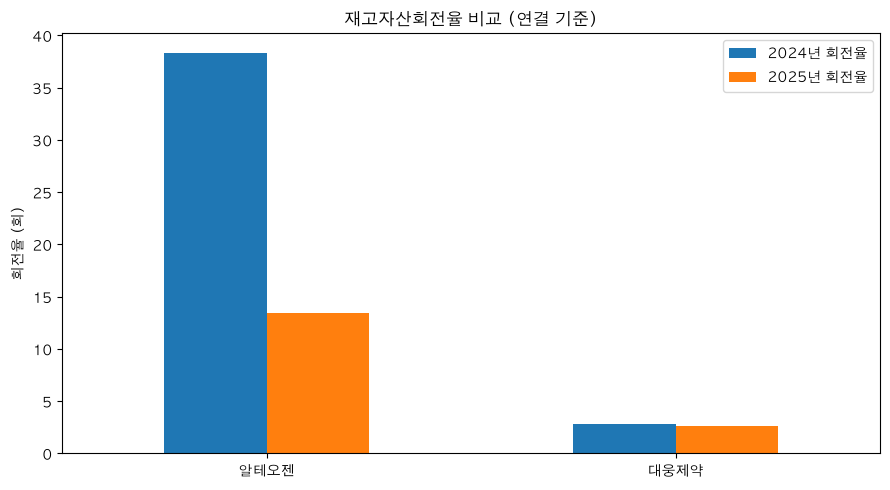

그래프 저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/inventory_turnover.png


In [17]:

import matplotlib.pyplot as plt
from pathlib import Path

output_dir = Path.home() / "BioAuditAnalyzer-2.0" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

# 한글 폰트: macOS
plt.rcParams["font.family"] = "AppleGothic"
plt.rcParams["axes.unicode_minus"] = False

chart_df = inventory_df.set_index("기업")[
    ["2024년 회전율", "2025년 회전율"]
]

ax = chart_df.plot(
    kind="bar",
    figsize=(9, 5),
    rot=0
)

ax.set_title("재고자산회전율 비교 (연결 기준)")
ax.set_ylabel("회전율 (회)")
ax.set_xlabel("")
ax.legend(title="")

plt.tight_layout()

chart_path = output_dir / "inventory_turnover.png"
plt.savefig(chart_path, dpi=200, bbox_inches="tight")
plt.show()

print("그래프 저장 완료:", chart_path)


In [18]:
csv_path = output_dir / "inventory_analysis.csv"

inventory_df.round(3).to_csv(
    csv_path,
    index=False,
    encoding="utf-8-sig"
)

print("분석표 저장 완료:", csv_path)

분석표 저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/inventory_analysis.csv


In [20]:
# 기존 함수 재사용
alteogen_fs_2024 = get_financial_statements(
    alteogen_code, year=2024
)

daewoong_fs_2024 = get_financial_statements(
    daewoong_code, year=2024
)

print("2024년 연결재무제표 수집 완료")

2024년 연결재무제표 수집 완료


In [21]:
checks = [
    ("매출액", "ifrs-full_Revenue", "CIS"),
    ("영업이익", "dart_OperatingIncomeLoss", "CIS"),
    ("매출원가", "ifrs-full_CostOfSales", "CIS"),
    ("재고자산", "ifrs-full_Inventories", "BS")
]

validation_results = []

for company, df_2025, df_2024 in [
    ("알테오젠", alteogen_fs, alteogen_fs_2024),
    ("대웅제약", daewoong_fs, daewoong_fs_2024)
]:
    for account, account_id, sj_div in checks:

        # 2025년 보고서의 전기 비교금액
        previous = get_amount(
            df_2025, account_id, sj_div, "frmtrm_amount"
        )

        # 2024년 보고서의 당기금액
        original = get_amount(
            df_2024, account_id, sj_div, "thstrm_amount"
        )

        validation_results.append({
            "기업": company,
            "계정": account,
            "2024년 원공시(억)": original / 1e8,
            "2025년 보고서 비교금액(억)": previous / 1e8,
            "차이(원)": previous - original,
            "검증결과": (
                "일치" if previous == original
                else "차이 확인 필요"
            )
        })

validation_df = pd.DataFrame(validation_results)

display(validation_df.round(2))

,기업,계정,2024년 원공시(억),2025년 보고서 비교금액(억),차이(원),검증결과
0,알테오젠,매출액,1028.55,1028.55,0,일치
1,알테오젠,영업이익,254.04,254.04,0,일치
2,알테오젠,매출원가,387.86,387.86,0,일치
3,알테오젠,재고자산,9.57,9.57,0,일치
4,대웅제약,매출액,14226.83,14226.83,0,일치
5,대웅제약,영업이익,1479.42,1479.42,0,일치
6,대웅제약,매출원가,6885.16,6885.16,0,일치
7,대웅제약,재고자산,2563.53,2563.53,0,일치


In [22]:
for company, df_2025, df_2024 in [
    ("알테오젠", alteogen_fs, alteogen_fs_2024),
    ("대웅제약", daewoong_fs, daewoong_fs_2024)
]:
    inv_2023_a = get_amount(
        df_2025, "ifrs-full_Inventories",
        "BS", "bfefrmtrm_amount"
    )

    inv_2023_b = get_amount(
        df_2024, "ifrs-full_Inventories",
        "BS", "frmtrm_amount"
    )

    print(
        company,
        "2023년 재고자산:",
        "일치" if inv_2023_a == inv_2023_b
        else "차이 확인 필요"
    )

알테오젠 2023년 재고자산: 일치
대웅제약 2023년 재고자산: 일치


In [23]:
from datetime import datetime, timezone

source_rows = []

for company, df in [
    ("알테오젠", alteogen_fs),
    ("대웅제약", daewoong_fs)
]:
    receipt_no = str(df["rcept_no"].dropna().iloc[0])

    source_rows.append({
        "기업": company,
        "사업연도": 2025,
        "보고서종류": "사업보고서",
        "재무제표기준": "연결(CFS)",
        "DART접수번호": receipt_no,
        "공시URL": (
            "https://dart.fss.or.kr/dsaf001/"
            f"main.do?rcpNo={receipt_no}"
        ),
        "자료확인시각_UTC": datetime.now(
            timezone.utc
        ).isoformat(timespec="seconds")
    })

source_df = pd.DataFrame(source_rows)

source_df.to_csv(
    output_dir / "source_manifest.csv",
    index=False,
    encoding="utf-8-sig"
)

display(source_df)

,기업,사업연도,보고서종류,재무제표기준,DART접수번호,공시URL,자료확인시각_UTC
0,알테오젠,2025,사업보고서,연결(CFS),20260323001596,https://dart.fss.or.kr/dsaf001/main.do?rcpNo=2...,2026-11-03T09:54:31+00:00
1,대웅제약,2025,사업보고서,연결(CFS),20260318001528,https://dart.fss.or.kr/dsaf001/main.do?rcpNo=2...,2026-11-03T09:54:31+00:00


In [24]:
validation_df.to_csv(
    output_dir / "validation_2024.csv",
    index=False,
    encoding="utf-8-sig"
)

In [25]:

# 매출 및 수익성 지표
revenue_data = financial_kpis[
    [
        "기업",
        "매출증가율(%)",
        "영업이익률_2025(%)",
        "영업이익률_2024(%)"
    ]
].copy()

# 자산총계와 무형자산
asset_data = analysis_df[
    analysis_df["계정"].isin(["자산총계", "무형자산"])
].pivot(
    index="기업",
    columns="계정",
    values="2025년(억 원)"
).reset_index()

# 기업별 데이터 결합
risk_input_2 = revenue_data.merge(
    asset_data,
    on="기업",
    validate="one_to_one"
)

# 무형자산 비중
risk_input_2["무형자산비중(%)"] = (
    risk_input_2["무형자산"]
    / risk_input_2["자산총계"]
    * 100
)

# 영업이익률 변화: 퍼센트포인트
risk_input_2["영업이익률변화(%p)"] = (
    risk_input_2["영업이익률_2025(%)"]
    - risk_input_2["영업이익률_2024(%)"]
)

display(risk_input_2.round(2))


,기업,매출증가율(%),영업이익률_2025(%),영업이익률_2024(%),무형자산,자산총계,무형자산비중(%),영업이익률변화(%p)
0,알테오젠,109.87,49.52,24.7,1201.19,6987.43,17.19,24.82
1,대웅제약,10.42,12.53,10.4,3675.24,23627.99,15.55,2.13


In [26]:

import pandas as pd

def detect_revenue_intangible_risks(
    row,
    revenue_growth_threshold=50,
    intangible_ratio_threshold=15
):
    signals = []
    company = row["기업"]

    revenue_growth = row["매출증가율(%)"]
    intangible_ratio = row["무형자산비중(%)"]

    # REV-01: 매출 증가율
    if (
        pd.notna(revenue_growth)
        and revenue_growth >= revenue_growth_threshold
    ):
        signals.append({
            "기업": company,
            "규칙": "REV-01",
            "검토 신호": "매출액의 큰 폭 증가",
            "근거": f"매출 증가율 {revenue_growth:.2f}%",
            "관련 기준": "K-IFRS 제1115호",
            "추천 PBC": (
                "매출 유형별 명세, "
                "주요 계약서, 수행의무 이행증빙"
            ),
            "검증방법": (
                "매출 증가 원인 분석 및 "
                "주요 계약의 수익인식 시점 검토"
            )
        })

    # INT-01: 총자산 대비 무형자산 비중
    if (
        pd.notna(intangible_ratio)
        and intangible_ratio >= intangible_ratio_threshold
    ):
        signals.append({
            "기업": company,
            "규칙": "INT-01",
            "검토 신호": "무형자산의 자산 내 비중이 높음",
            "근거": f"총자산 대비 {intangible_ratio:.2f}%",
            "관련 기준": (
                "K-IFRS 제1038호 / 제1036호"
            ),
            "추천 PBC": (
                "무형자산 구성·변동명세, "
                "개발비 자산화 검토자료, 손상검토 자료"
            ),
            "검증방법": (
                "무형자산 구성 파악 후 "
                "자산화 및 손상검토 대상 확인"
            )
        })

    return signals


new_signals = []

for _, row in risk_input_2.iterrows():
    new_signals.extend(
        detect_revenue_intangible_risks(row)
    )

new_risk_report = pd.DataFrame(new_signals)

display(new_risk_report)


,기업,규칙,검토 신호,근거,관련 기준,추천 PBC,검증방법
0,알테오젠,REV-01,매출액의 큰 폭 증가,매출 증가율 109.87%,K-IFRS 제1115호,"매출 유형별 명세, 주요 계약서, 수행의무 이행증빙",매출 증가 원인 분석 및 주요 계약의 수익인식 시점 검토
1,알테오젠,INT-01,무형자산의 자산 내 비중이 높음,총자산 대비 17.19%,K-IFRS 제1038호 / 제1036호,"무형자산 구성·변동명세, 개발비 자산화 검토자료, 손상검토 자료",무형자산 구성 파악 후 자산화 및 손상검토 대상 확인
2,대웅제약,INT-01,무형자산의 자산 내 비중이 높음,총자산 대비 15.55%,K-IFRS 제1038호 / 제1036호,"무형자산 구성·변동명세, 개발비 자산화 검토자료, 손상검토 자료",무형자산 구성 파악 후 자산화 및 손상검토 대상 확인


In [29]:

import pandas as pd

# 매출 증가율
revenue_data = financial_kpis[
    ["기업", "매출증가율(%)"]
].copy()

# 재고자산 증가율
inventory_growth = analysis_df.loc[
    analysis_df["계정"] == "재고자산",
    ["기업", "증가율(%)"]
].rename(columns={
    "증가율(%)": "재고증가율(%)"
})

# 재고자산회전율
turnover_data = inventory_df[
    ["기업", "2024년 회전율", "2025년 회전율"]
].copy()

# 세 데이터 결합
risk_input = (
    revenue_data
    .merge(
        inventory_growth,
        on="기업",
        validate="one_to_one"
    )
    .merge(
        turnover_data,
        on="기업",
        validate="one_to_one"
    )
)

display(risk_input.round(2))


,기업,매출증가율(%),재고증가율(%),2024년 회전율,2025년 회전율
0,알테오젠,109.87,582.44,38.30,13.42
1,대웅제약,10.42,21.27,2.77,2.64


In [30]:

def detect_inventory_risks(
    row,
    growth_gap_threshold=15,
    turnover_decline_threshold=5
):
    signals = []

    company = row["기업"]

    revenue_growth = row["매출증가율(%)"]
    inventory_growth = row["재고증가율(%)"]

    turnover_2024 = row["2024년 회전율"]
    turnover_2025 = row["2025년 회전율"]

    # Rule 01: 재고 증가율과 매출 증가율 비교
    growth_gap = inventory_growth - revenue_growth

    if pd.notna(growth_gap) and growth_gap >= growth_gap_threshold:
        signals.append({
            "기업": company,
            "규칙": "INV-01",
            "검토 신호": "재고자산 증가율이 매출 증가율을 크게 상회",
            "근거": f"증가율 격차 {growth_gap:.2f}%p",
            "관련 기준": "K-IFRS 제1002호",
            "추천 PBC": "재고 연령분석표, LOT별 유효기간, NRV 평가표",
            "검증방법": "재고 증가 원인과 평가손실의 적정성 확인"
        })

    # Rule 02: 재고자산회전율 하락 여부
    if pd.notna(turnover_2024) and turnover_2024 > 0:
        decline_rate = (
            (turnover_2024 - turnover_2025)
            / turnover_2024
        ) * 100

        if (
            pd.notna(decline_rate)
            and decline_rate >= turnover_decline_threshold
        ):
            signals.append({
                "기업": company,
                "규칙": "INV-02",
                "검토 신호": "재고자산회전율 하락",
                "근거": f"전년 대비 {decline_rate:.2f}% 하락",
                "관련 기준": "K-IFRS 제1002호",
                "추천 PBC": "재고수불부, 판매실적, 생산계획",
                "검증방법": "재고 누적 원인과 판매 가능성 분석"
            })

    return signals


# 두 기업에 탐지 규칙 적용
all_signals = []

for _, row in risk_input.iterrows():
    all_signals.extend(detect_inventory_risks(row))

risk_report = pd.DataFrame(all_signals)

if risk_report.empty:
    print("설정한 조건에 해당하는 추가 검토 신호 없음")
else:
    display(risk_report)


,기업,규칙,검토 신호,근거,관련 기준,추천 PBC,검증방법
0,알테오젠,INV-01,재고자산 증가율이 매출 증가율을 크게 상회,증가율 격차 472.57%p,K-IFRS 제1002호,"재고 연령분석표, LOT별 유효기간, NRV 평가표",재고 증가 원인과 평가손실의 적정성 확인
1,알테오젠,INV-02,재고자산회전율 하락,전년 대비 64.97% 하락,K-IFRS 제1002호,"재고수불부, 판매실적, 생산계획",재고 누적 원인과 판매 가능성 분석


In [31]:
from pathlib import Path

output_dir = Path.home() / "BioAuditAnalyzer-2.0" / "outputs"
output_dir.mkdir(parents=True, exist_ok=True)

risk_report.to_csv(
    output_dir / "audit_risk_signals.csv",
    index=False,
    encoding="utf-8-sig"
)

print("위험 탐지 결과 저장 완료")

위험 탐지 결과 저장 완료


In [32]:

from pathlib import Path

# 기존 재고자산 신호 + 신규 매출·무형자산 신호
combined_report = pd.concat(
    [risk_report, new_risk_report],
    ignore_index=True
)

# 동일 기업에서 동일 규칙이 중복 기록되지 않도록 확인
if not combined_report.empty:
    assert not combined_report.duplicated(
        subset=["기업", "규칙"]
    ).any(), "중복된 탐지 규칙이 있습니다."

# GitHub 프로젝트 출력 폴더
output_dir = (
    Path.home() / "BioAuditAnalyzer-2.0" / "outputs"
)
output_dir.mkdir(parents=True, exist_ok=True)

# 전체 위험 신호 저장
report_path = output_dir / "audit_risk_report.csv"

combined_report.to_csv(
    report_path,
    index=False,
    encoding="utf-8-sig"
)

print("분석 대상 기업:", risk_input_2["기업"].tolist())
print("탐지된 검토 신호:", len(combined_report), "건")
print("저장 완료:", report_path)

display(combined_report)


분석 대상 기업: ['알테오젠', '대웅제약']
탐지된 검토 신호: 5 건
저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/audit_risk_report.csv


,기업,규칙,검토 신호,근거,관련 기준,추천 PBC,검증방법
0,알테오젠,INV-01,재고자산 증가율이 매출 증가율을 크게 상회,증가율 격차 472.57%p,K-IFRS 제1002호,"재고 연령분석표, LOT별 유효기간, NRV 평가표",재고 증가 원인과 평가손실의 적정성 확인
1,알테오젠,INV-02,재고자산회전율 하락,전년 대비 64.97% 하락,K-IFRS 제1002호,"재고수불부, 판매실적, 생산계획",재고 누적 원인과 판매 가능성 분석
2,알테오젠,REV-01,매출액의 큰 폭 증가,매출 증가율 109.87%,K-IFRS 제1115호,"매출 유형별 명세, 주요 계약서, 수행의무 이행증빙",매출 증가 원인 분석 및 주요 계약의 수익인식 시점 검토
3,알테오젠,INT-01,무형자산의 자산 내 비중이 높음,총자산 대비 17.19%,K-IFRS 제1038호 / 제1036호,"무형자산 구성·변동명세, 개발비 자산화 검토자료, 손상검토 자료",무형자산 구성 파악 후 자산화 및 손상검토 대상 확인
4,대웅제약,INT-01,무형자산의 자산 내 비중이 높음,총자산 대비 15.55%,K-IFRS 제1038호 / 제1036호,"무형자산 구성·변동명세, 개발비 자산화 검토자료, 손상검토 자료",무형자산 구성 파악 후 자산화 및 손상검토 대상 확인


In [33]:
# 무형자산 비중 기준을 15%에서 20%로 변경
for _, row in risk_input_2.iterrows():
    signals = detect_revenue_intangible_risks(
        row,
        revenue_growth_threshold=50,
        intangible_ratio_threshold=20
    )

    print(
        row["기업"],
        "탐지 규칙:",
        [signal["규칙"] for signal in signals]
    )

알테오젠 탐지 규칙: ['REV-01']
대웅제약 탐지 규칙: []


In [1]:

# 규칙별 추천 PBC 데이터베이스

PBC_CATALOG = {
    "INV-01": [
        {
            "감사주장": "평가",
            "요청자료": "품목별 재고 연령분석표",
            "검증목적": "장기체화 재고 식별",
            "검증절차": "장기 미판매 품목 및 보유기간 확인"
        },
        {
            "감사주장": "평가",
            "요청자료": "LOT별 유효기간 및 NRV 평가표",
            "검증목적": "재고평가손실의 적정성 검토",
            "검증절차": "유효기간, 예상판매가격 및 처분비용 검토"
        }
    ],

    "INV-02": [
        {
            "감사주장": "실재성·완전성",
            "요청자료": "재고수불부 및 품목별 재고명세",
            "검증목적": "재고 변동 및 누적 원인 파악",
            "검증절차": "입출고 기록과 재고명세의 일치 여부 확인"
        },
        {
            "감사주장": "평가",
            "요청자료": "품목별 판매실적 및 생산계획",
            "검증목적": "보유 재고의 판매 가능성 검토",
            "검증절차": "실제 판매량과 향후 판매계획 비교"
        }
    ],

    "REV-01": [
        {
            "감사주장": "발생사실·기간귀속",
            "요청자료": "주요 매출계약서 및 변경계약서",
            "검증목적": "수익인식 조건 확인",
            "검증절차": "수행의무와 수익인식 시점 검토"
        },
        {
            "감사주장": "발생사실·정확성",
            "요청자료": "매출 유형별 명세 및 이행증빙",
            "검증목적": "매출 증가 원인 및 금액 검토",
            "검증절차": "원장과 계약·이행증빙 대조"
        }
    ],

    "INT-01": [
        {
            "감사주장": "분류·평가",
            "요청자료": "무형자산 구성 및 변동명세",
            "검증목적": "무형자산의 구성과 변동 원인 확인",
            "검증절차": "계정별 증감 및 관련 증빙 대조"
        },
        {
            "감사주장": "평가",
            "요청자료": "개발비 자산화 및 손상검토 자료",
            "검증목적": "해당 자산의 인식·손상 요건 검토",
            "검증절차": "자산 유형과 개발단계, 손상징후 및 회수가능액 검토"
        }
    ]
}

print("PBC 추천 규칙:", len(PBC_CATALOG), "개")


PBC 추천 규칙: 4 개


In [2]:

import pandas as pd
from pathlib import Path

output_dir = Path.home() / "BioAuditAnalyzer-2.0" / "outputs"

# 이전 교시에서 저장한 위험 신호 결과
signal_df = pd.read_csv(
    output_dir / "audit_risk_report.csv",
    encoding="utf-8-sig"
)

# 정의되지 않은 규칙이 있는지 검증
unknown_rules = set(signal_df["규칙"]) - set(PBC_CATALOG)

if unknown_rules:
    raise ValueError(
        f"PBC 정보가 없는 규칙: {unknown_rules}"
    )

pbc_rows = []

for _, signal in signal_df.iterrows():
    rule_id = signal["규칙"]

    for pbc in PBC_CATALOG[rule_id]:
        pbc_rows.append({
            "기업": signal["기업"],
            "규칙": rule_id,
            "검토 신호": signal["검토 신호"],
            "관련 기준": signal["관련 기준"],
            **pbc
        })

pbc_df = pd.DataFrame(pbc_rows)

print("위험 신호:", len(signal_df), "건")
print("추천 PBC 항목:", len(pbc_df), "건")

display(pbc_df)


위험 신호: 5 건
추천 PBC 항목: 10 건


,기업,규칙,검토 신호,관련 기준,감사주장,요청자료,검증목적,검증절차
0,알테오젠,INV-01,재고자산 증가율이 매출 증가율을 크게 상회,K-IFRS 제1002호,평가,품목별 재고 연령분석표,장기체화 재고 식별,장기 미판매 품목 및 보유기간 확인
1,알테오젠,INV-01,재고자산 증가율이 매출 증가율을 크게 상회,K-IFRS 제1002호,평가,LOT별 유효기간 및 NRV 평가표,재고평가손실의 적정성 검토,"유효기간, 예상판매가격 및 처분비용 검토"
2,알테오젠,INV-02,재고자산회전율 하락,K-IFRS 제1002호,실재성·완전성,재고수불부 및 품목별 재고명세,재고 변동 및 누적 원인 파악,입출고 기록과 재고명세의 일치 여부 확인
3,알테오젠,INV-02,재고자산회전율 하락,K-IFRS 제1002호,평가,품목별 판매실적 및 생산계획,보유 재고의 판매 가능성 검토,실제 판매량과 향후 판매계획 비교
4,알테오젠,REV-01,매출액의 큰 폭 증가,K-IFRS 제1115호,발생사실·기간귀속,주요 매출계약서 및 변경계약서,수익인식 조건 확인,수행의무와 수익인식 시점 검토
5,알테오젠,REV-01,매출액의 큰 폭 증가,K-IFRS 제1115호,발생사실·정확성,매출 유형별 명세 및 이행증빙,매출 증가 원인 및 금액 검토,원장과 계약·이행증빙 대조
6,알테오젠,INT-01,무형자산의 자산 내 비중이 높음,K-IFRS 제1038호 / 제1036호,분류·평가,무형자산 구성 및 변동명세,무형자산의 구성과 변동 원인 확인,계정별 증감 및 관련 증빙 대조
7,알테오젠,INT-01,무형자산의 자산 내 비중이 높음,K-IFRS 제1038호 / 제1036호,평가,개발비 자산화 및 손상검토 자료,해당 자산의 인식·손상 요건 검토,"자산 유형과 개발단계, 손상징후 및 회수가능액 검토"
8,대웅제약,INT-01,무형자산의 자산 내 비중이 높음,K-IFRS 제1038호 / 제1036호,분류·평가,무형자산 구성 및 변동명세,무형자산의 구성과 변동 원인 확인,계정별 증감 및 관련 증빙 대조
9,대웅제약,INT-01,무형자산의 자산 내 비중이 높음,K-IFRS 제1038호 / 제1036호,평가,개발비 자산화 및 손상검토 자료,해당 자산의 인식·손상 요건 검토,"자산 유형과 개발단계, 손상징후 및 회수가능액 검토"


In [3]:
pbc_path = output_dir / "pbc_request_list.csv"

pbc_df.to_csv(
    pbc_path,
    index=False,
    encoding="utf-8-sig"
)

print("PBC 추천 목록 저장 완료:", pbc_path)

PBC 추천 목록 저장 완료: /Users/kosunjin/BioAuditAnalyzer-2.0/outputs/pbc_request_list.csv


In [5]:
import sys
from pathlib import Path

project_root = Path.home() / "BioAuditAnalyzer-2.0"

# 프로젝트 최상위 폴더를 Python 검색 경로에 추가
if str(project_root) not in sys.path:
    sys.path.insert(0, str(project_root))

# 우리가 직접 만든 모듈 불러오기
from src.risk_engine import build_risk_report
from src.pbc_engine import build_pbc_report

print("모듈 불러오기 성공!")

모듈 불러오기 성공!


In [7]:
import pandas as pd
from pathlib import Path

# 1. 저장된 CSV 파일 불러오기
project_root = Path.home() / "BioAuditAnalyzer-2.0"
output_dir = project_root / "outputs"

financial_kpis = pd.read_csv(
    output_dir / "financial_kpis_2025.csv"
)

analysis_df = pd.read_csv(
    output_dir / "financial_growth_2025.csv"
)

inventory_df = pd.read_csv(
    output_dir / "inventory_analysis.csv"
)


# 2. 재고자산 증가율 추출
inventory_growth = analysis_df.loc[
    analysis_df["계정"] == "재고자산",
    ["기업", "증가율(%)"]
].rename(columns={
    "증가율(%)": "재고증가율(%)"
})


# 3. 무형자산 비중 계산
asset_data = analysis_df[
    analysis_df["계정"].isin(["자산총계", "무형자산"])
].pivot(
    index="기업",
    columns="계정",
    values="2025년(억 원)"
).reset_index()

asset_data["무형자산비중(%)"] = (
    asset_data["무형자산"]
    / asset_data["자산총계"]
    * 100
)


# 4. 모든 분석 데이터 결합
engine_input = (
    financial_kpis[["기업", "매출증가율(%)"]]
    .merge(inventory_growth, on="기업", validate="one_to_one")
    .merge(
        inventory_df[
            ["기업", "2024년 회전율", "2025년 회전율"]
        ],
        on="기업",
        validate="one_to_one"
    )
    .merge(
        asset_data[["기업", "무형자산비중(%)"]],
        on="기업",
        validate="one_to_one"
    )
)

print("분석 데이터 준비 완료!")
display(engine_input.round(2))


# 5. 모듈화한 함수 실행
modular_risk_report = build_risk_report(engine_input)

modular_pbc_report = build_pbc_report(
    modular_risk_report
)

print("검토 신호:", len(modular_risk_report), "건")
print("추천 PBC:", len(modular_pbc_report), "건")

display(modular_risk_report)
display(modular_pbc_report)

분석 데이터 준비 완료!


,기업,매출증가율(%),재고증가율(%),2024년 회전율,2025년 회전율,무형자산비중(%)
0,알테오젠,109.87,582.44,38.30,13.42,17.19
1,대웅제약,10.42,21.27,2.77,2.64,15.55


검토 신호: 5 건
추천 PBC: 10 건


,기업,규칙,검토 신호,근거,관련 기준
0,알테오젠,INV-01,재고 증가율이 매출 증가율을 크게 상회,증가율 격차 472.57%p,K-IFRS 제1002호
1,알테오젠,INV-02,재고자산회전율 하락,전년 대비 64.97% 하락,K-IFRS 제1002호
2,알테오젠,REV-01,매출액의 큰 폭 증가,매출 증가율 109.87%,K-IFRS 제1115호
3,알테오젠,INT-01,무형자산 비중이 높음,총자산 대비 17.19%,K-IFRS 제1038호 / 제1036호
4,대웅제약,INT-01,무형자산 비중이 높음,총자산 대비 15.55%,K-IFRS 제1038호 / 제1036호


,기업,규칙,검토 신호,관련 기준,감사주장,요청자료,검증목적,검증절차
0,알테오젠,INV-01,재고 증가율이 매출 증가율을 크게 상회,K-IFRS 제1002호,평가,품목별 재고 연령분석표,장기체화 재고 식별,장기 미판매 품목과 보유기간 확인
1,알테오젠,INV-01,재고 증가율이 매출 증가율을 크게 상회,K-IFRS 제1002호,평가,LOT별 유효기간 및 NRV 평가표,평가손실 적정성 검토,유효기간과 순실현가능가치 검토
2,알테오젠,INV-02,재고자산회전율 하락,K-IFRS 제1002호,평가,재고수불부 및 품목별 재고명세,재고 누적 원인 파악,입출고 변동과 재고명세 대조
3,알테오젠,INV-02,재고자산회전율 하락,K-IFRS 제1002호,평가,판매실적 및 생산계획,재고 판매 가능성 검토,실제 판매량과 향후 판매계획 비교
4,알테오젠,REV-01,매출액의 큰 폭 증가,K-IFRS 제1115호,발생사실·기간귀속,주요 매출계약서 및 변경계약서,수익인식 조건 검토,계약조건 및 수행의무 식별
5,알테오젠,REV-01,매출액의 큰 폭 증가,K-IFRS 제1115호,발생사실·정확성,매출 유형별 명세 및 이행증빙,매출 증가 원인 검토,매출원장과 수행의무 이행증빙 대조
6,알테오젠,INT-01,무형자산 비중이 높음,K-IFRS 제1038호 / 제1036호,분류·평가,무형자산 구성 및 변동명세,무형자산의 구성 확인,자산별 증감 및 계정분류 검토
7,알테오젠,INT-01,무형자산 비중이 높음,K-IFRS 제1038호 / 제1036호,평가,개발비 자산화 및 손상검토 자료,해당 자산의 인식·평가 검토,자산 종류에 따른 자산화·손상 검토
8,대웅제약,INT-01,무형자산 비중이 높음,K-IFRS 제1038호 / 제1036호,분류·평가,무형자산 구성 및 변동명세,무형자산의 구성 확인,자산별 증감 및 계정분류 검토
9,대웅제약,INT-01,무형자산 비중이 높음,K-IFRS 제1038호 / 제1036호,평가,개발비 자산화 및 손상검토 자료,해당 자산의 인식·평가 검토,자산 종류에 따른 자산화·손상 검토


In [8]:
import pandas as pd

output_dir = project_root / "outputs"
old_path = output_dir / "audit_risk_report.csv"

if old_path.exists():
    old_report = pd.read_csv(old_path, encoding="utf-8-sig")

    # 두 결과의 기업·규칙 조합 비교
    old_keys = set(
        zip(old_report["기업"], old_report["규칙"])
    )
    new_keys = set(
        zip(
            modular_risk_report["기업"],
            modular_risk_report["규칙"]
        )
    )

    assert old_keys == new_keys, (
        "기존 결과와 신규 결과의 탐지 규칙이 다릅니다."
    )

    print("기존 결과와 탐지 규칙 일치!")
else:
    print("기존 보고서가 없어 비교 검증을 생략합니다.")

기존 결과와 탐지 규칙 일치!


In [9]:
# 기존 파일을 보존하면서 새 결과 저장
modular_risk_report.to_csv(
    output_dir / "audit_risk_report_modular.csv",
    index=False,
    encoding="utf-8-sig"
)

modular_pbc_report.to_csv(
    output_dir / "pbc_request_list_modular.csv",
    index=False,
    encoding="utf-8-sig"
)

print("모듈화 결과 저장 완료!")

모듈화 결과 저장 완료!
